<style>
  .MathJax, .MathJax_Display, mjx-container, .mjx-chtml, .mjx-math { direction: ltr !important; }
  pre, code { direction: ltr !important; text-align: left !important; unicode-bidi: embed; }
</style>

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 📚 תקשורת אופטית (83-466), אוניברסיטת בר-אילן 2026
### **מרצה: ד"ר בוריס דסיאטוב**

---

## צעדים ראשונים ב-Tidy3D: מציאת האופנים (Modes) של סיבים אופטיים ומוליכי גל

ברוכים הבאים! בהרצאות מצאנו את **האופנים** של סיב אופטי על הנייר: פונקציות בסל, גרף $b$–$V$, ותנאי הקיטעון $V = 2.405$.
במחברת הזו תלמדו איך לתת למחשב למצוא את האופנים בשבילכם, עבור **כל** חתך רוחב שתוכלו לשרטט.

### 🤔 מהו אופן, ומהו "פותר אופנים" (Mode Solver)?
**אופן** הוא תבנית שדה $\mathbf{E}(x,y)$ שמתקדמת לאורך הסיב (ציר $z$) **בלי לשנות את צורתה**:

$$\mathbf{E}(x,y,z,t) = \mathbf{E}(x,y)\, e^{i(\beta z - \omega t)}, \qquad \beta = n_{\text{eff}}\,\frac{2\pi}{\lambda_0}$$

לכל אופן יש **מקדם שבירה אפקטיבי** $n_{\text{eff}}$ משלו (כמה מהר הוא מתקדם) ו**פרופיל שדה** משלו (איך הוא נראה).
**פותר אופנים** מקבל את חתך הרוחב (איפה הליבה, מהם מקדמי השבירה, ובאיזה אורך גל) ופותר את משוואות מקסוול במישור הדו-ממדי הזה.
הוא מחזיר רשימה של אופנים, ולכל אחד את ה-$n_{\text{eff}}$ שלו ואת ששת רכיבי השדה $E_x, E_y, E_z, H_x, H_y, H_z$.

### 🎯 מה תלמדו
| חלק | נושא |
|---|---|
| **0** | איך מריצים את המחברת + קורס בזק בפייתון (NumPy, Matplotlib) |
| **1** | איך Tidy3D "חושב": חומרים, גיאומטריה, סימולציה, פותר אופנים, תוצאות |
| **2** | דוגמה מודרכת: **סיב** Step-Index עם כמה אופנים |
| **3** | דוגמה מודרכת: **מוליך גל** מלבני על שבב |
| **4** | דף עזר, טעויות נפוצות, ואיפה למצוא עזרה |

> 💡 **איך לעבוד עם המחברת:** הריצו את התאים **לפי הסדר**, מלמעלה למטה (`Shift + Enter` מריץ תא).
> קראו את ההסבר, הריצו את הקוד, הסתכלו על הגרף, ואז **שנו מספר והריצו שוב**. זו הדרך המהירה ביותר ללמוד.
> הדוגמאות כאן משתמשות במבנים ובפרמטרים שונים מאלה שבמטלת הבית, ולכן תצטרכו להתאים את הקוד בעצמכם.

<sub>Bar-Ilan University 2026 · Optical Communication 83-466 · Dr. Boris Desiatov</sub>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 🧰 חלק 0: מתחילים

## 0.1 איפה מריצים את המחברת

### ⭐ מומלץ: סביבת ה-Jupyter המקוונת של Tidy3D
**הדרך המומלצת** בקורס היא להריץ את המחברת בתוך **סביבת ה-Jupyter המקוונת של Tidy3D** (פלטפורמת הרשת של Flexcompute).
Tidy3D, ‏NumPy ו-Matplotlib כבר מותקנים שם, והחשבון שלכם כבר מחובר, כך שאין צורך בשום התקנה.
הקורס קיבל **קרדיטים של Tidy3D** לצורך זה.

1. היכנסו לפלטפורמת הרשת של Tidy3D ([tidy3d.simulation.cloud](https://tidy3d.simulation.cloud)) עם פרטי החשבון שקיבלתם בקורס.
2. פתחו את אזור ה-**Notebooks** (Jupyter) ו**העלו** את קובץ ה-`.ipynb` הזה.
3. פתחו אותו והריצו את התאים לפי הסדר, מלמעלה למטה.

> 💳 **לגבי קרדיטים:** פותר האופנים במחברת הזו רץ בתוך המחברת עצמה, ולכן הוא לא צורך קרדיטים.
> קרדיטים נצרכים רק כששולחים סימולציה גדולה לשרתי הענן של Flexcompute (באמצעות `tidy3d.web`), ואת זה אנחנו לא עושים כאן.

### אפשרויות נוספות (אם אתם מעדיפים)
**אפשרות א': Google Colab (בלי התקנה).**
1. היכנסו ל-[colab.research.google.com](https://colab.research.google.com) ← *File* ← *Upload notebook* ← בחרו את קובץ ה-`.ipynb` הזה.
2. הריצו את התאים לפי הסדר. תא הקוד הראשון מתקין את Tidy3D אוטומטית (כדקה, רק פעם אחת בכל הפעלה).

**אפשרות ב': על המחשב שלכם.**
1. התקינו Python (גרסה 3.10 ומעלה), ואז בטרמינל: `pip install tidy3d jupyter`
2. הריצו `jupyter notebook` (או פתחו את הקובץ ב-VS Code עם תוסף Jupyter).

### 🔑 האם צריך מפתח API ב-Colab או במחשב שלי?
**לא.** **פותר האופנים** שבו אנחנו משתמשים רץ **מקומית**, ולכן הוא עובד גם ב-Colab או במחשב שלכם, בלי חשבון ובלי מפתח API.
במחברת הזו לא נשתמש אף פעם ב-`tidy3d.web`.

## 0.2 התקנה וייבוא של החבילות
התא הבא בודק אם Tidy3D מותקן, ומתקין אותו אם הוא חסר (בסביבה המקוונת של Tidy3D הוא כבר מותקן, ולכן השלב הזה מדולג). אחר כך הוא מייבא את שלוש החבילות שבהן נשתמש:

| חבילה | שם מקוצר | מה היא עושה בשבילנו |
|---|---|---|
| **NumPy** | `np` | מערכים של מספרים וחישובים עליהם (`np.sqrt`, `np.pi`, `np.linspace`, …) |
| **Matplotlib** | `plt` | גרפים: גרפי קו, מפות צבע, איורים עם כמה חלונות |
| **Tidy3D** | `td` | בונה את המבנה ופותר את האופנים |

</div>

In [1]:
# --- Install Tidy3D if it is not installed yet (takes ~1 minute on Colab, only the first time) ---
import importlib.util, subprocess, sys
if importlib.util.find_spec("tidy3d") is None:
    print("Installing tidy3d ... please wait")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tidy3d"])

# --- Imports: we give each package a short nickname ---
import time                          # to measure how long a calculation takes
import numpy as np                   # numbers and arrays
import matplotlib.pyplot as plt      # plotting
import tidy3d as td                  # the electromagnetic solver
from tidy3d.plugins.mode import ModeSolver   # the mode solver itself

# Hide Tidy3D's informational messages, keep only real errors
td.config.logging.level = "ERROR"

# Bigger fonts so plots are easy to read
plt.rcParams.update({"font.size": 13, "figure.dpi": 100})

print("Tidy3D version:", td.__version__)

Tidy3D version: 2.12.2


<div dir="rtl" style="text-align: right; line-height: 1.6;">

## 0.3 קורס בזק בפייתון (5 דקות)
אם אתם כבר מכירים פייתון, דלגו ל**חלק 1**. אחרת, הריצו כל תא וקראו את ההערות (הטקסט שאחרי `#`).

### משתנים, הדפסה ו-f-strings
משתנה שומר ערך. `print()` מציג אותו. **f-string** (`f"..."`) מאפשר לשלב משתנים בתוך טקסט;
`{x:.4f}` פירושו "הדפס את `x` עם 4 ספרות אחרי הנקודה".

</div>

In [2]:
n1 = 1.50          # refractive index of the core  (a number)
n2 = 1.47          # refractive index of the cladding
wavelength = 1.31  # in micrometers (µm)

delta = (n1 - n2) / n1          # relative index difference
print("Delta =", delta)
print(f"Delta = {delta:.4f}  ({100*delta:.2f} %)")   # nicer formatting

Delta = 0.020000000000000018
Delta = 0.0200  (2.00 %)


<div dir="rtl" style="text-align: right; line-height: 1.6;">

### רשימות ולולאות `for`
**רשימה** מחזיקה כמה ערכים: `[a, b, c]`. **לולאת `for`** חוזרת על השורות המוזחות פעם אחת לכל איבר ברשימה.
תבנית נפוצה מאוד: מתחילים ב**רשימה ריקה**, ובתוך הלולאה מוסיפים לה תוצאה אחת בכל סיבוב עם **`append`**.

</div>

In [3]:
cladding_indices = [1.40, 1.44, 1.47, 1.49]    # a list of 4 values

critical_angles = []                            # empty list, we will fill it
for n_clad in cladding_indices:                 # n_clad takes each value in turn
    theta_c = np.degrees(np.arcsin(n_clad / n1))   # critical angle (Snell's law)
    critical_angles.append(theta_c)                 # store the result
    print(f"n_clad = {n_clad:.2f}  ->  critical angle = {theta_c:.1f} deg")

print("All results:", critical_angles)

n_clad = 1.40  ->  critical angle = 69.0 deg
n_clad = 1.44  ->  critical angle = 73.7 deg
n_clad = 1.47  ->  critical angle = 78.5 deg
n_clad = 1.49  ->  critical angle = 83.4 deg
All results: [np.float64(68.96053021868275), np.float64(73.73979529168804), np.float64(78.52165904546642), np.float64(83.3803722047161)]


<div dir="rtl" style="text-align: right; line-height: 1.6;">

### פונקציות
**פונקציה** אורזת כמה שורות קוד תחת שם אחד, כדי שאפשר יהיה להשתמש בהן שוב. `def` מגדיר אותה, ו-`return` מחזיר את התוצאה.

</div>

In [4]:
def critical_angle_deg(n_core, n_clad):
    # Return the critical angle (in degrees) for total internal reflection.
    return np.degrees(np.arcsin(n_clad / n_core))

print(critical_angle_deg(1.5, 1.0))     # glass -> air
print(critical_angle_deg(1.5, 1.45))    # glass -> slightly lower-index glass

41.810314895778596
75.16488841802426


<div dir="rtl" style="text-align: right; line-height: 1.6;">

### מערכי NumPy ו"מסכות"
**מערך** של NumPy דומה לרשימה, אבל אפשר לחשב על **כל האיברים בבת אחת** (בלי לולאה).
השוואה כמו `arr > 1.45` מחזירה מערך של `True`/`False` שנקרא **מסכה** (mask). אפשר להשתמש במסכה כדי לבחור איברים, או כדי לספור אותם עם `np.sum`.

</div>

In [5]:
values = np.array([1.452, 1.449, 1.446, 1.441, 1.437])   # some numbers
print("values * 2      =", values * 2)                    # math on every element
print("np.sqrt(values) =", np.sqrt(values))

lower, upper = 1.440, 1.450
mask = (values > lower) & (values < upper)     # & means "and"; each condition in ( )
print("mask            =", mask)
print("selected values =", values[mask])
print("how many?       =", np.sum(mask))       # True counts as 1, False as 0

x = np.linspace(0, 10, 6)      # 6 equally spaced numbers from 0 to 10
print("linspace        =", x)

values * 2      = [2.904 2.898 2.892 2.882 2.874]
np.sqrt(values) = [1.20498963 1.20374416 1.2024974  1.20041659 1.19874935]
mask            = [False  True  True  True False]
selected values = [1.449 1.446 1.441]
how many?       = 3
linspace        = [ 0.  2.  4.  6.  8. 10.]


<div dir="rtl" style="text-align: right; line-height: 1.6;">

### גרפים עם Matplotlib
המתכון תמיד זהה: יוצרים איור וצירים (`fig, ax = plt.subplots()`), מציירים על הצירים, ומוסיפים תוויות.

</div>

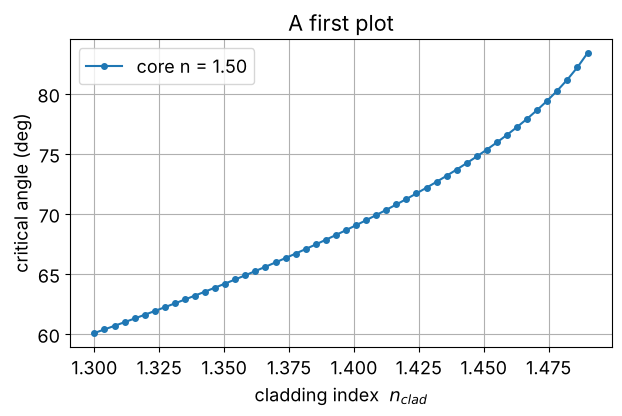

In [6]:
n_clad_values = np.linspace(1.30, 1.49, 50)              # 50 points
theta_c = critical_angle_deg(1.50, n_clad_values)        # works on the whole array at once

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_clad_values, theta_c, "o-", markersize=4, label="core n = 1.50")
ax.set_xlabel("cladding index  $n_{clad}$")
ax.set_ylabel("critical angle (deg)")
ax.set_title("A first plot")
ax.grid(True)
ax.legend()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

**מפת צבע** מציגה מערך דו-ממדי (למשל שדה $|E(x,y)|^2$) כצבעים. `pcolormesh(x, y, Z)` מצייר אותה, ו-`colorbar` מוסיף את סרגל הערכים.
כאן נצייר כתם גאוסי, שנראה מאוד דומה לאופן היסוד של סיב.

</div>

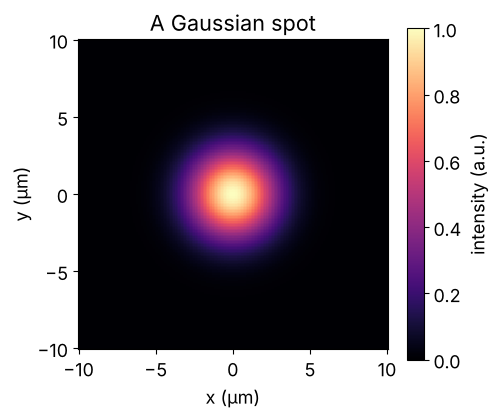

In [7]:
x = np.linspace(-10, 10, 201)          # µm
y = np.linspace(-10, 10, 201)
X, Y = np.meshgrid(x, y)               # 2D grids of x and y coordinates
w0 = 4.0                               # spot radius (µm)
intensity = np.exp(-2 * (X**2 + Y**2) / w0**2)

fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.pcolormesh(X, Y, intensity, cmap="magma", shading="auto")
fig.colorbar(im, ax=ax, label="intensity (a.u.)")
ax.set_aspect("equal")                 # so a circle looks like a circle
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax.set_title("A Gaussian spot")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 🧠 חלק 1: איך Tidy3D "חושב"

כל חישוב אופנים ב-Tidy3D בנוי מאותן 5 לבנים. מספיק ללמוד אותן פעם אחת, ואפשר למדל כל סיב או מוליך גל:

<div dir="ltr" style="text-align: left;">

```
 Medium     ->  what the material is        (refractive index)
 Geometry   ->  what shape it has           (Cylinder, Box, ...)
 Structure  =   Geometry + Medium           ("a cylinder made of glass")
 Simulation ->  the world: size, grid, background material, list of structures
 ModeSolver ->  "find the modes in this plane"   ->  .solve()  ->  results (n_eff, fields)
```

</div>


| לבנה | בעברית |
|---|---|
| `Medium` | החומר (מקדם השבירה) |
| `Geometry` | הצורה (גליל, תיבה, …) |
| `Structure` | צורה + חומר ("גליל עשוי זכוכית") |
| `Simulation` | "העולם": גודל, רשת, חומר רקע, רשימת המבנים |
| `ModeSolver` | "מצא את האופנים במישור הזה" ← `.solve()` ← תוצאות ($n_{\text{eff}}$, שדות) |

## 1.1 יחידות וצירים
* **יחידת האורך = מיקרומטר (µm).** `1.55` פירושו 1.55 µm. תמיד.
* האור מתקדם לאורך ציר **z**. חתך הרוחב (המישור שבו מחפשים אופנים) הוא **מישור x–y**.
* לכן לאזור סימולציה דו-ממדי יש גודל `(Lx, Ly, 0)`: רוחב `Lx`, גובה `Ly`, ועובי אפס לאורך $z$.
* התדר הוא $f = c_0/\lambda_0$. ‏Tidy3D נותן את מהירות האור כ-`td.C_0` (ביחידות µm/s), ולכן `freq = td.C_0 / wavelength`.

</div>

In [8]:
wavelength = 1.55                  # µm
freq = td.C_0 / wavelength         # Hz
print(f"c0 = {td.C_0:.4e} µm/s")
print(f"wavelength = {wavelength} µm  ->  frequency = {freq/1e12:.1f} THz")

c0 = 2.9979e+14 µm/s
wavelength = 1.55 µm  ->  frequency = 193.4 THz


<div dir="rtl" style="text-align: right; line-height: 1.6;">

## 1.2 חומרים: `td.Medium`
עבור זכוכית פשוטה וללא הפסדים, נותנים את **המקדם הדיאלקטרי היחסי** $\varepsilon_r = n^2$:
<div dir="ltr" style="text-align: left;">

```python
glass = td.Medium(permittivity=n**2)
```

</div>

ל-Tidy3D יש גם **ספריית חומרים** (material library) עם חומרים אמיתיים שנמדדו במעבדה ותלויים באורך הגל (סיליקה, סיליקון, סיליקון ניטריד, …).
לא תצטרכו אותה במחברת הזו, אבל כך מוצאים את מקדם השבירה של סיליקה באורך גל 1.55 µm:

</div>

In [9]:
core_glass = td.Medium(permittivity=1.46**2, name="core glass")   # constant index 1.46
print("core permittivity =", core_glass.permittivity)

silica = td.material_library["SiO2"]["Horiba"]        # real, dispersive silica
n, k = silica.nk_model(td.C_0 / 1.55)                 # n and k at one frequency
print(f"library SiO2 at 1.55 µm: n = {float(n):.4f}, k = {float(k):.1e}")

core permittivity = 2.1315999999999997
library SiO2 at 1.55 µm: n = 1.4577, k = 2.2e-04


<div dir="rtl" style="text-align: right; line-height: 1.6;">

## 1.3 גיאומטריה ומבנה (Structure)
| צורה | קוד | משמעות |
|---|---|---|
| גליל (ליבת סיב) | `td.Cylinder(center=(0,0,0), radius=a, length=td.inf, axis=2)` | מוט עגול ברדיוס `a`, אינסופי באורכו, שצירו לאורך **z** (`axis=2`; ‏x=0, y=1, z=2) |
| תיבה (ליבת מוליך גל) | `td.Box(center=(0,0,0), size=(W, H, td.inf))` | מלבן ברוחב `W` (בכיוון x) ובגובה `H` (בכיוון y), אינסופי בכיוון z |

`td.inf` פירושו "אינסופי באורכו": המבנה זהה בכל $z$, וזה בדיוק מה שמוליך גל הוא.

**Structure** מחבר צורה לחומר:
<div dir="ltr" style="text-align: left;">

```python
core = td.Structure(geometry=td.Cylinder(...), medium=core_glass)
```

</div>

**המעטפת** (cladding) בדרך כלל איננה מבנה בכלל: היא **חומר הרקע** של הסימולציה (כל מה שאינו ליבה).

## 1.4 הסימולציה: "העולם"
<div dir="ltr" style="text-align: left;">

```python
sim = td.Simulation(
    size=(Lx, Ly, 0),               # the calculation window (µm); 0 along z -> a 2D plane
    structures=[core],              # list of all structures (here only the core)
    medium=cladding_glass,          # background material = cladding
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=15, wavelength=wavelength),  # mesh
    run_time=1e-12,                 # required by Tidy3D, not used by the mode solver
)
```

</div>

* **`size`**: גודל חלון החישוב. החלון צריך להיות **גדול מספיק** כך שהשדה של האופן כמעט דועך לאפס בשוליים.
* **`grid_spec`**: ‏Tidy3D מחלק את החלון לתאים קטנים (רשת, mesh). `min_steps_per_wvl=15` פירושו לפחות 15 תאים לכל אורך גל **בתוך החומר**.
  יותר תאים ← דיוק גבוה יותר, אבל יותר זמן ויותר זיכרון.
* **`run_time`**: משמש רק בסימולציות בתחום הזמן (FDTD). פותר האופנים מתעלם ממנו, אבל חייבים לתת ערך.

נבנה דוגמה קטנה (מוט זכוכית) ו**תמיד נסתכל עליה לפני שפותרים**:

</div>

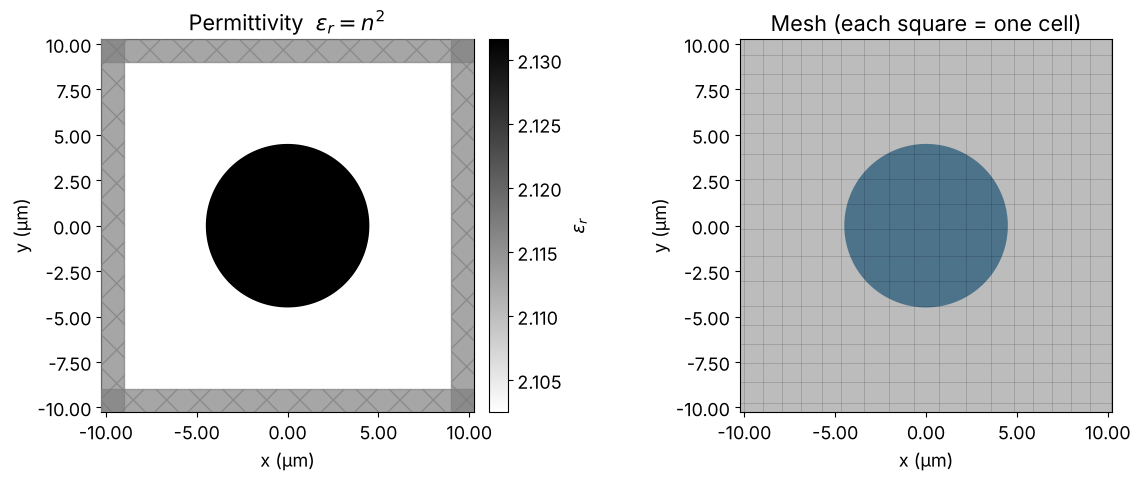

number of cells (x, y, z): [195, 195, 1]


In [10]:
# --- example structure: a glass rod (fiber core) in slightly lower-index glass ---
example_core = td.Structure(
    geometry=td.Cylinder(center=(0, 0, 0), radius=4.5, length=td.inf, axis=2),
    medium=td.Medium(permittivity=1.46**2),
)
example_sim = td.Simulation(
    size=(18, 18, 0),
    structures=[example_core],
    medium=td.Medium(permittivity=1.45**2),
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=10, wavelength=1.55),
    run_time=1e-12,
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), tight_layout=True)
example_sim.plot_eps(z=0, ax=ax[0])        # permittivity map: is the core where I think it is?
example_sim.plot_grid(z=0, ax=ax[1])       # the mesh
example_sim.plot_structures(z=0, ax=ax[1]) # structure outline on top of the mesh
ax[0].set_title("Permittivity  $\\varepsilon_r = n^2$")
ax[1].set_title("Mesh (each square = one cell)")
plt.show()
print("number of cells (x, y, z):", example_sim.grid.num_cells)

<div dir="rtl" style="text-align: right; line-height: 1.6;">

הפס האפור המקווקו סביב החלון הוא **PML** (שכבה בולעת ש-Tidy3D מוסיף לסימולציות בתחום הזמן). פותר האופנים לא משתמש בו; הוא מסתכל רק בתוך המישור שנותנים לו.

## 1.5 פותר האופנים: `ModeSpec` + `ModeSolver`
שני אובייקטים:

**`td.ModeSpec`**: *מה* לחפש.
* `num_modes`: כמה אופנים להחזיר. הפותר תמיד מחזיר בדיוק את המספר הזה, **גם אם בפועל פחות אופנים מולכים** (נרחיב בהמשך).
* `target_neff`: "חפש אופנים עם $n_{\text{eff}}$ קרוב לערך הזה". השתמשו ב**מקדם השבירה של הליבה**, כך שהפותר יתחיל לחפש מהאופנים המולכים ביותר.

**`ModeSolver`**: *איפה ובאיזה תדר* לחפש.
* `simulation`: "העולם" שבניתם למעלה.
* `plane`: ‏`td.Box` עם ממד אחד שווה לאפס: חתך הרוחב. בדרך כלל כל החלון: `td.Box(center=(0,0,0), size=(Lx, Ly, 0))`.
* `freqs`: **רשימה** של תדרים, למשל `[td.C_0 / wavelength]`.

אחר כך `.solve()` מריץ את החישוב ומחזיר **אובייקט תוצאות** (`ModeSolverData`).

</div>

In [11]:
example_solver = ModeSolver(
    simulation=example_sim,
    plane=td.Box(center=(0, 0, 0), size=(18, 18, 0)),
    mode_spec=td.ModeSpec(num_modes=4, target_neff=1.46),
    freqs=[td.C_0 / 1.55],
)

t0 = time.time()
example_data = example_solver.solve()          # <-- the actual calculation
print(f"solved in {time.time() - t0:.1f} s")

solved in 2.0 s


<div dir="rtl" style="text-align: right; line-height: 1.6;">

## 1.6 מה יש בתוך התוצאות?
| מה | קוד | צורה / משמעות |
|---|---|---|
| מקדמי שבירה אפקטיביים | `data.n_eff` | ערך אחד לכל (תדר, אופן) |
| אותו דבר, כ-NumPy רגיל | `data.n_eff.values` | מערך דו-ממדי `[תדר, אופן]`; עם תדר אחד משתמשים ב-`data.n_eff.values[0]` |
| רכיב שדה | `data.Ex`, `data.Ey`, `data.Ez`, `data.Hx`, … | שדה מרוכב על הרשת, עם התוויות `x, y, z, f, mode_index` |
| $\lvert E\rvert^2$ הכולל | `data.intensity` | $\lvert E_x\rvert^2+\lvert E_y\rvert^2+\lvert E_z\rvert^2$ על הרשת |
| גרף מוכן | `solver.plot_field("Ey", mode_index=0)` | מפת צבע של רכיב אחד של אופן אחד |

השדות הם מערכי **xarray**: מערכי NumPy שנושאים איתם גם את הקואורדינטות (ה-`x` וה-`y` של כל נקודה). זה מאוד נוח, כפי שתראו.

</div>

In [12]:
neff = example_data.n_eff.values[0]        # n_eff of all modes at our (single) frequency
for i, n in enumerate(neff):               # enumerate gives the index i and the value n
    print(f"mode {i}:  n_eff = {n:.6f}")

mode 0:  n_eff = 1.456689
mode 1:  n_eff = 1.456689
mode 2:  n_eff = 1.452196
mode 3:  n_eff = 1.452190


<div dir="rtl" style="text-align: right; line-height: 1.6;">

### ציור שדות עם `plot_field`
`solver.plot_field(field_name, val=..., mode_index=..., ax=...)`

* `field_name`: ‏`"Ex"`, `"Ey"`, `"Ez"`, `"Hx"`, … או `"E"` עבור השדה החשמלי הכולל.
* `val`: מה להציג: `"real"` (החלק הממשי, מראה את **הסימן**, כך שרואים צמתים ואונות), `"abs"` ($|E|$), או `"abs^2"` ($|E|^2$, העוצמה).
* `mode_index`: איזה אופן (0 = האופן עם ה-$n_{\text{eff}}$ הגבוה ביותר).
* `ax`: על איזה חלון לצייר. אחר כך אפשר להתקרב (zoom) עם `ax.set_xlim(...)`.

</div>

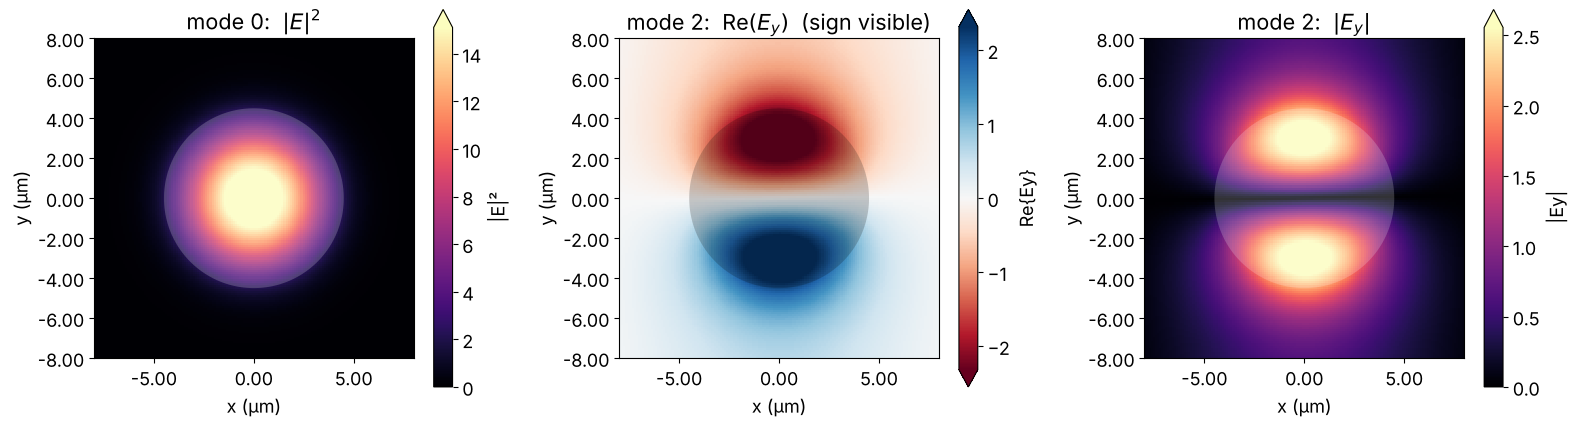

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), tight_layout=True)
example_solver.plot_field("E",  val="abs^2", mode_index=0, ax=ax[0])
example_solver.plot_field("Ey", val="real",  mode_index=2, ax=ax[1])
example_solver.plot_field("Ey", val="abs",   mode_index=2, ax=ax[2])
ax[0].set_title("mode 0:  $|E|^2$")
ax[1].set_title("mode 2:  Re$(E_y)$  (sign visible)")
ax[2].set_title("mode 2:  $|E_y|$")
for a in ax:
    a.set_xlim(-8, 8); a.set_ylim(-8, 8)
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

### הוצאת המספרים הגולמיים (לחישובים משלכם)
`plot_field` מצוין כדי להסתכל, אבל כדי **לחשב** משהו (סכום, יחס, רוחב…) צריך את המספרים.
ארבעת הכלים שתצטרכו:

| כלי | דוגמה | מה הוא עושה |
|---|---|---|
| `.isel(...)` | `data.Ey.isel(mode_index=0, f=0)` | בחירה לפי **מיקום** (אופן מספר 0, התדר הראשון) |
| `.squeeze()` | `....squeeze()` | מוריד ממדים באורך 1 (כמו `z`) ← מפה דו-ממדית נקייה |
| `.x`, `.y`, `.values` | `E.x.values` | צירי הקואורדינטות והנתונים כ-NumPy רגיל |
| `.where(mask, 0)` | `I.where(I.x > 0, 0)` | שומר ערכים במקומות שבהם המסכה `True`, ושם 0 בכל השאר |
| `.integrate(...)` | `I.integrate(["x", "y"])` | $\iint I(x,y)\,dx\,dy$, לפי גודל התאים האמיתי |

> ⚠️ **למה `.integrate` ולא `np.sum`?** הרשת של Tidy3D **אינה אחידה**: התאים יכולים להיות קטנים יותר ליד שפות הליבה.
> `np.sum` מחבר ערכים בלי שטח התאים, ולכן נותן משקלים שגויים. `.integrate` משתמש ב-$dx\,dy$ האמיתי של כל תא.

למטה ניקח את $|E|^2$ של אופן 0 כמערך דו-ממדי, נצייר אותו בעצמנו עם `pcolormesh`, ונבצע אינטגרל על **החצי הימני** של החלון ($x > 0$), כדוגמה לאינטגרציה על אזור.

</div>

dimensions: ('x', 'y')   shape: (174, 174)
fraction of |E|^2 in x > 0:  0.500   (symmetric mode -> about 0.5)


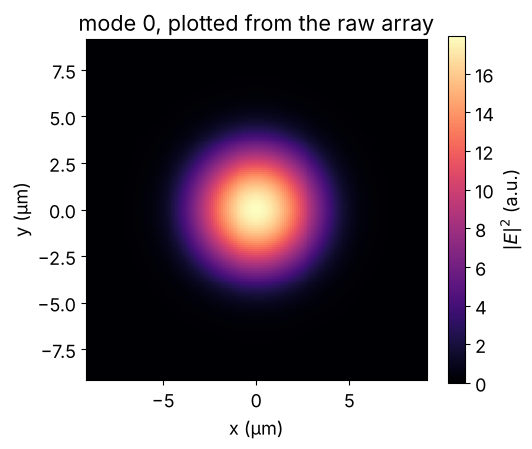

In [14]:
I0 = example_data.intensity.isel(mode_index=0, f=0).squeeze()   # |E|^2 of mode 0, 2D
print("dimensions:", I0.dims, "  shape:", I0.shape)

x = I0.x.values        # 1D array of x coordinates (µm)
y = I0.y.values        # 1D array of y coordinates (µm)

# integral over the whole window, and over the region x > 0
total      = float(I0.integrate(["x", "y"]))
right_half = float(I0.where(I0.x > 0, 0).integrate(["x", "y"]))
print(f"fraction of |E|^2 in x > 0:  {right_half / total:.3f}   (symmetric mode -> about 0.5)")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.pcolormesh(x, y, I0.values.T, cmap="magma", shading="auto")   # .T: rows must be y
fig.colorbar(im, ax=ax, label="$|E|^2$ (a.u.)")
ax.set_aspect("equal"); ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax.set_title("mode 0, plotted from the raw array")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

> 📌 **הערה על `.T` (שחלוף):** המערך שמור בסדר `[x, y]`, אבל `pcolormesh` מצפה שהשורות יהיו `y` והעמודות `x`. לכן מעבירים `I0.values.T`.

</div>

---

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 🧵 חלק 2: דוגמה מודרכת: סיב Step-Index עם כמה אופנים

עכשיו נחבר את הלבנים לסיב אמיתי. בחרנו סיב שמוליך **כמה** אופנים, כדי שיהיה הרבה מה לראות:

| פרמטר | ערך |
|---|---|
| אורך גל $\lambda_0$ | 0.85 µm (אורך גל נפוץ לטווחים קצרים) |
| רדיוס הליבה $a$ | 5 µm |
| מקדם שבירה של הליבה $n_1$ | 1.460 |
| מקדם שבירה של המעטפת $n_2$ | 1.455 |

### 2.1 קודם, התאוריה שאתם כבר מכירים
מההרצאות: $\text{NA} = \sqrt{n_1^2 - n_2^2}$ ו-$V = \dfrac{2\pi a}{\lambda_0}\,\text{NA}$.
אופן הוא **מולך** רק אם מקדם השבירה האפקטיבי שלו נמצא בין שני המקדמים:
$$n_2 < n_{\text{eff}} < n_1$$

</div>

In [15]:
# ---- fiber parameters (all lengths in µm) ----
wl_fib = 0.85      # wavelength
a_fib  = 5.0       # core radius
n_core = 1.460
n_clad = 1.455

NA = np.sqrt(n_core**2 - n_clad**2)
V  = 2 * np.pi * a_fib / wl_fib * NA
print(f"NA = {NA:.4f}")
print(f"V  = {V:.3f}")

NA = 0.1207
V  = 4.462


<div dir="rtl" style="text-align: right; line-height: 1.6;">

עם $V \approx 4.5$ אנחנו מצפים לסיב עם כמה אופנים (סיב חד-אופני דורש $V < 2.405$). בואו נראה מה Tidy3D מוצא.

### 2.2 בניית הסיב
נעטוף את הבנייה ב**פונקציה**, `make_fiber_solver(...)`. כך בחלק 2.5 נוכל לבנות הרבה סיבים בלולאה, פשוט על ידי קריאה לפונקציה עם מספרים אחרים.

</div>

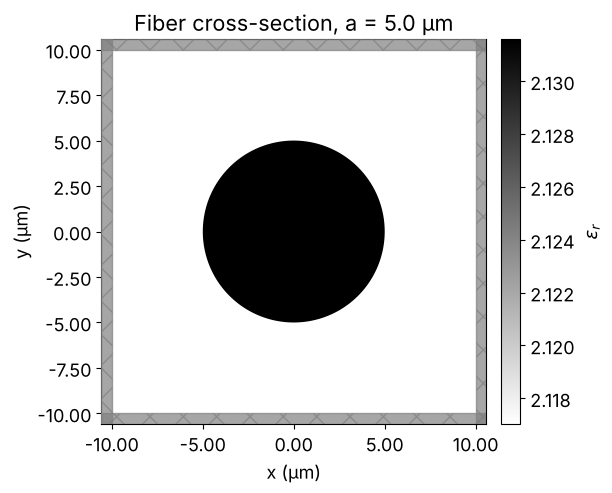

In [16]:
def make_fiber_solver(radius, wavelength, n_core, n_clad, window, num_modes, steps=12):
    # Build a step-index fiber (core along z) and return a ready-to-run ModeSolver.
    core = td.Structure(
        geometry=td.Cylinder(center=(0, 0, 0), radius=radius, length=td.inf, axis=2),
        medium=td.Medium(permittivity=n_core**2),
    )
    sim = td.Simulation(
        size=(window, window, 0),
        structures=[core],
        medium=td.Medium(permittivity=n_clad**2),        # cladding = background
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=steps, wavelength=wavelength),
        run_time=1e-12,
    )
    return ModeSolver(
        simulation=sim,
        plane=td.Box(center=(0, 0, 0), size=(window, window, 0)),
        mode_spec=td.ModeSpec(num_modes=num_modes, target_neff=n_core),
        freqs=[td.C_0 / wavelength],
    )

fiber_solver = make_fiber_solver(radius=a_fib, wavelength=wl_fib, n_core=n_core,
                                 n_clad=n_clad, window=20, num_modes=14)

# Always look before you solve
fig, ax = plt.subplots(figsize=(5.5, 5))
fiber_solver.simulation.plot_eps(z=0, ax=ax)
ax.set_title(f"Fiber cross-section, a = {a_fib} µm")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

### 2.3 פתרון ומיון האופנים ל"מולכים" ו"לא מולכים"
נבקש 14 אופנים. זה לוקח כחצי דקה (יותר ב-Colab). סיבים עם ניגודיות נמוכה במקדם השבירה צריכים חלון גדול והרבה תאים, ולכן הם המבנים האיטיים ביותר במחברת.

</div>

In [17]:
t0 = time.time()
fiber_data = fiber_solver.solve()
print(f"solved in {time.time() - t0:.1f} s\n")

def is_guided(neff, n_core, n_clad):
    # True for modes whose effective index lies between the cladding and core index.
    return (neff > n_clad) & (neff < n_core)

neff_fib = fiber_data.n_eff.values[0]
guided   = is_guided(neff_fib, n_core, n_clad)

print(" mode |   n_eff    | guided?")
print("------+------------+--------")
for i in range(len(neff_fib)):
    print(f"  {i:2d}  |  {neff_fib[i]:.6f}  |  {'yes' if guided[i] else 'no'}")
print(f"\nNumber of guided modes found: {np.sum(guided)}  (out of {len(neff_fib)} requested)")

solved in 26.3 s

 mode |   n_eff    | guided?
------+------------+--------
   0  |  1.459043  |  yes
   1  |  1.459043  |  yes
   2  |  1.457624  |  yes
   3  |  1.457623  |  yes
   4  |  1.457623  |  yes
   5  |  1.457621  |  yes
   6  |  1.455873  |  yes
   7  |  1.455873  |  yes
   8  |  1.455869  |  yes
   9  |  1.455869  |  yes
  10  |  1.455454  |  yes
  11  |  1.455454  |  yes
  12  |  1.454543  |  no
  13  |  1.454543  |  no

Number of guided modes found: 12  (out of 14 requested)


<div dir="rtl" style="text-align: right; line-height: 1.6;">

**שימו לב:**
* הפותר החזיר את **כל 14** האופנים שביקשנו, אבל רק חלקם מקיימים $n_2 < n_{\text{eff}} < n_1$. האחרים **אינם אופנים מולכים אמיתיים**:
  אלה אופני מעטפת / "קופסה" שקיימים רק משום שלחלון שלנו יש קירות. תמיד סננו אותם.
* הרבה ערכי $n_{\text{eff}}$ מופיעים ב**קבוצות של ערכים (כמעט) שווים**. זכרו את זה בכל פעם שאתם **סופרים** אופנים, והשוו למה שהתאוריה מההרצאה צופה.
* אם **כל** האופנים שהוחזרו מולכים, כנראה ביקשתם מעט מדי: הגדילו את `num_modes` עד שבסוף הרשימה יופיעו גם אופנים לא מולכים.

### 2.4 גלריה של האופנים המולכים
נצייר את $|E|^2$ של כל אופן מולך בחלון משלו. זו דוגמה טובה לשימוש בלולאה כדי למלא רשת של גרפים.

</div>

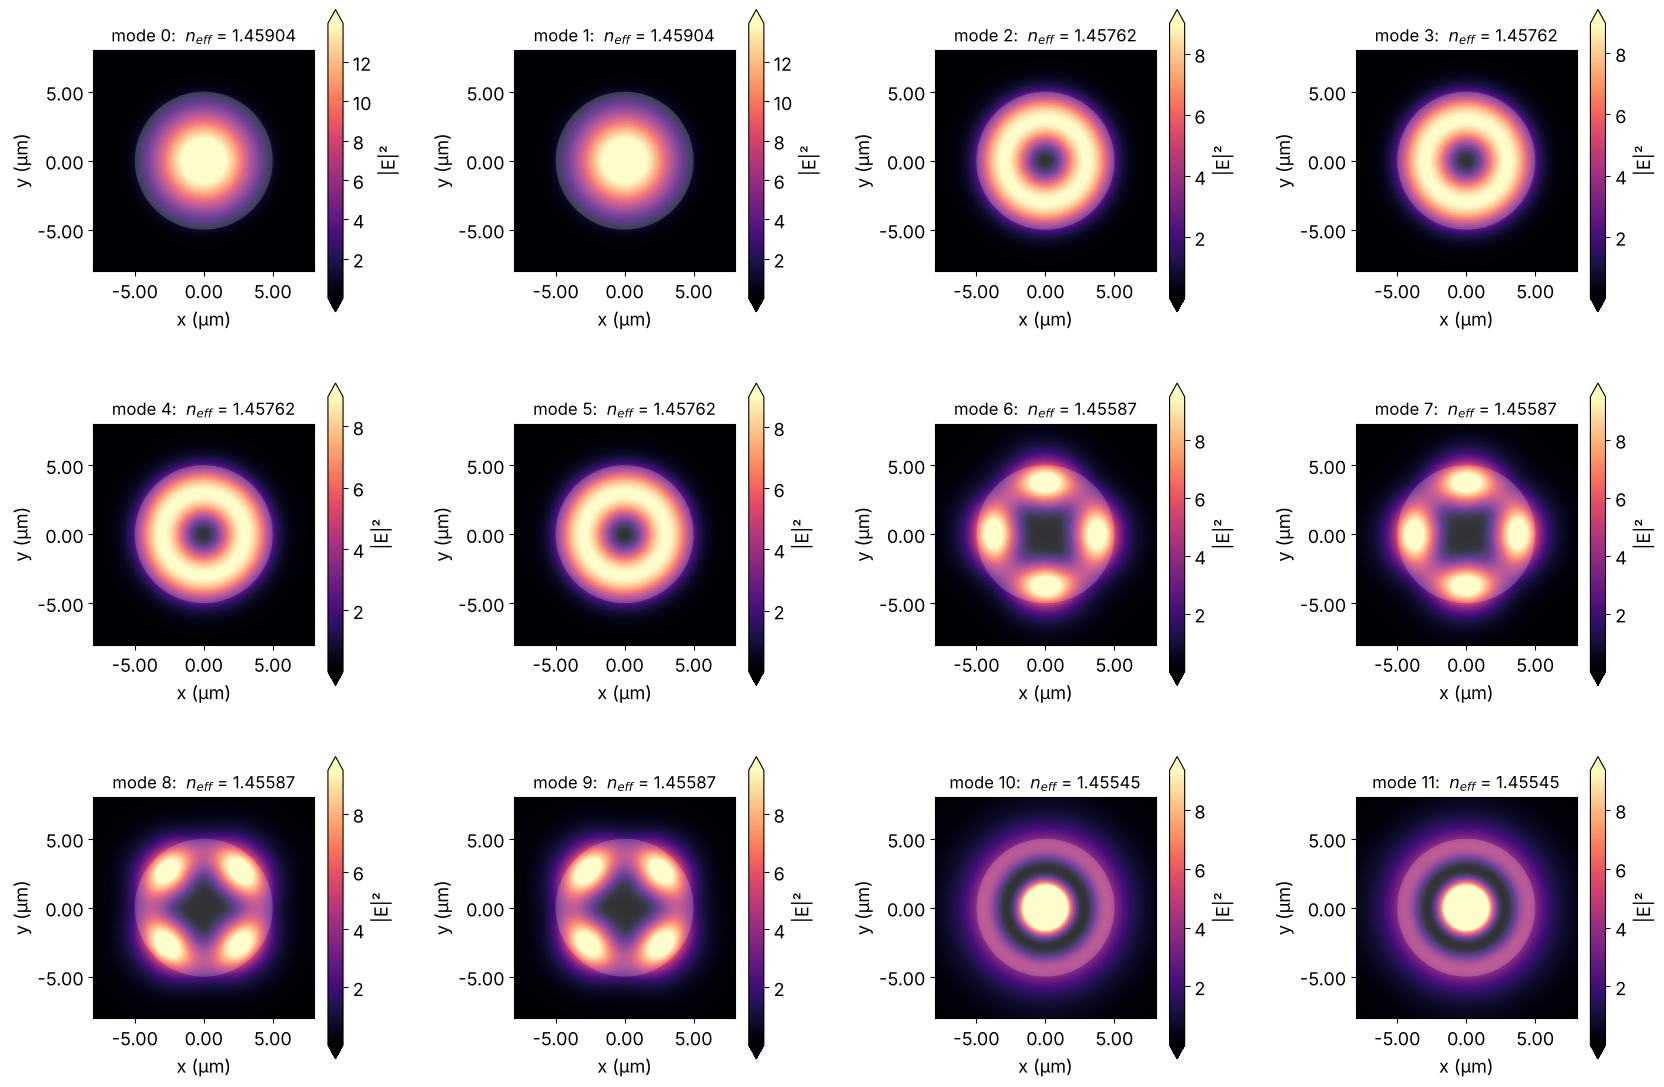

In [18]:
guided_idx = np.where(guided)[0]          # indices of the guided modes
ncols = 4
nrows = int(np.ceil(len(guided_idx) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows), tight_layout=True)
axes = axes.flatten()                     # turn the 2D grid of panels into a simple list

for k, m in enumerate(guided_idx):
    fiber_solver.plot_field("E", val="abs^2", mode_index=m, ax=axes[k])
    axes[k].set_title(f"mode {m}:  $n_{{eff}}$ = {neff_fib[m]:.5f}", fontsize=12)
    axes[k].set_xlim(-8, 8); axes[k].set_ylim(-8, 8)
for k in range(len(guided_idx), len(axes)):   # hide empty panels
    axes[k].axis("off")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

$|E|^2$ מראה **איפה** האור נמצא, אבל לא את **כיוון** השדה החשמלי.
כדי לראות את האופי הווקטורי של אופן, מסתכלים על כל רכיב בנפרד. הנה שלושת רכיבי השדה החשמלי של אחד האופנים מסדר גבוה:

</div>

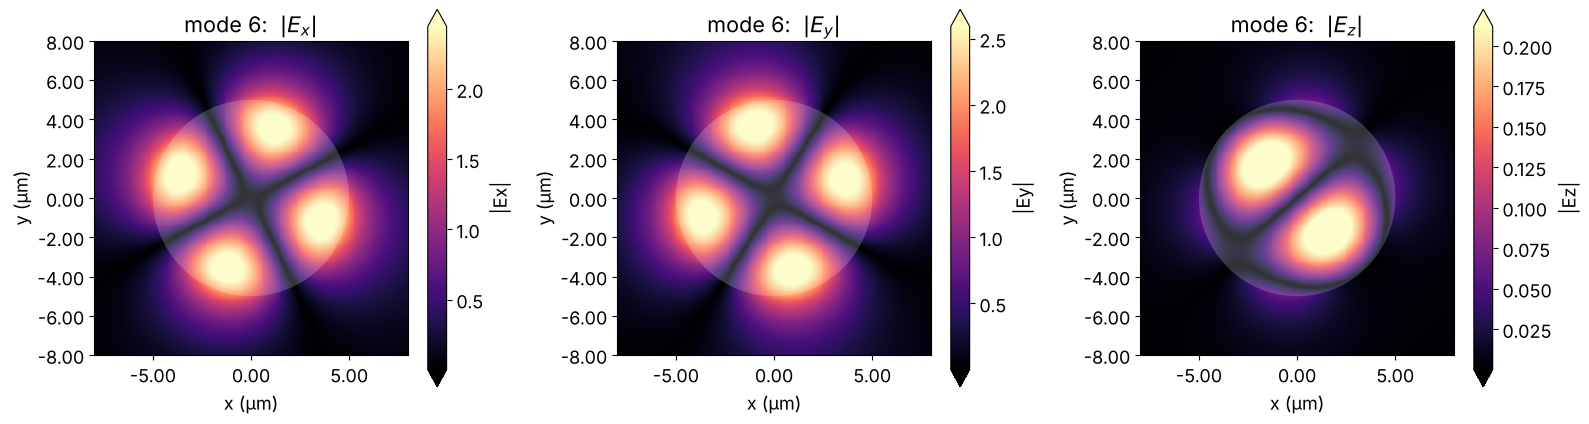

In [19]:
m = guided_idx[6]          # pick one of the guided modes (change this number!)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), tight_layout=True)
for a, comp in zip(ax, ["Ex", "Ey", "Ez"]):
    fiber_solver.plot_field(comp, val="abs", mode_index=m, ax=a)
    a.set_title(f"mode {m}:  $|{comp[0]}_{comp[1]}|$")
    a.set_xlim(-8, 8); a.set_ylim(-8, 8)
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

* קווים כהים הם **צמתים** (קווים שבהם השדה אפס). השוו את ערכי סרגל הצבע כדי לראות איזה רכיב חזק ואיזה חלש.
* $E_z$ (הרכיב בכיוון ההתקדמות) חלש בהרבה מ-$E_x, E_y$ בסיב בעל הנחיה חלשה.
* נסו `val="real"` במקום `"abs"`: תראו את **הסימן** של $E_x$ ו-$E_y$ (אונות אדומות/כחולות). אבל $E_z$ ייראה ריק!
  הסיבה היא ש-$E_z$ מתנודד בהפרש פאזה של 90° מהשדה הרוחבי, ולכן הוא כמעט **מדומה** לגמרי. נסו עבורו `val="imag"`.
  המסקנה: כשגרף נראה ריק, בדקו את סרגל הצבע ונסו `"abs"`.
* עכשיו נסו `m = guided_idx[2]`. עבור האופן הזה $E_z$ הוא בפועל **אפס** (הסתכלו על סרגל הצבע: ~$10^{-4}$, רק רעש נומרי בשפת הליבה).
  לחלק מאופני הסיב אין רכיב שדה חשמלי אורכי בכלל. האם תוכלו לקבוע מתוך $E_x$ ו-$E_y$ לאיזה כיוון השדה מצביע?

### 2.5 סריקת פרמטר: שינוי רדיוס הליבה
מחקר טיפוסי: **משנים פרמטר אחד בלולאה, פותרים בכל פעם, שומרים את התוצאות, ומציירים אותן.**
כאן נשנה את **רדיוס הליבה** $a$ ונשאיר את כל השאר קבוע. לכל רדיוס נשמור את כל ערכי $n_{\text{eff}}$ ואת מספר האופנים המולכים.

> ⏱️ התא הזה פותר 4 סיבים ולוקח כ-1–3 דקות. החלון גדל יחד עם הרדיוס, כך שהשדה תמיד נכנס בו.

</div>

In [20]:
radii = [2.0, 3.0, 4.0, 5.0]       # µm

V_list, n_guided_list, neff_list = [], [], []
for a in radii:
    solver = make_fiber_solver(radius=a, wavelength=wl_fib, n_core=n_core, n_clad=n_clad,
                               window=2 * a + 10, num_modes=14)
    t0 = time.time()
    data = solver.solve()
    neff = data.n_eff.values[0]

    V_list.append(2 * np.pi * a / wl_fib * NA)
    n_guided_list.append(np.sum(is_guided(neff, n_core, n_clad)))
    neff_list.append(neff)
    print(f"a = {a:.1f} µm   V = {V_list[-1]:.2f}   guided modes = {n_guided_list[-1]:2d}   ({time.time() - t0:.0f} s)")

a = 2.0 µm   V = 1.78   guided modes =  2   (12 s)


a = 3.0 µm   V = 2.68   guided modes =  6   (14 s)


a = 4.0 µm   V = 3.57   guided modes =  6   (22 s)


a = 5.0 µm   V = 4.46   guided modes = 12   (27 s)


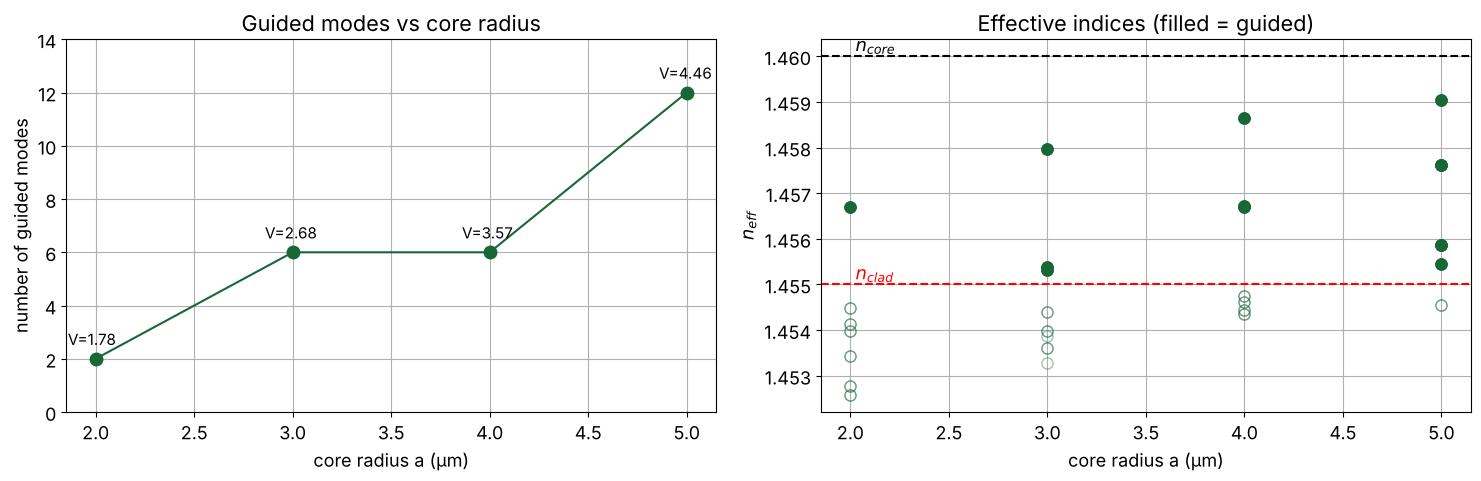

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), tight_layout=True)

# Left: number of guided modes vs radius
ax[0].plot(radii, n_guided_list, "o-", markersize=9)
for a, n, v in zip(radii, n_guided_list, V_list):
    ax[0].annotate(f"V={v:.2f}", (a, n), textcoords="offset points", xytext=(-20, 10), fontsize=11)
ax[0].set_xlabel("core radius a (µm)"); ax[0].set_ylabel("number of guided modes")
ax[0].set_ylim(0, max(n_guided_list) + 2)
ax[0].set_title("Guided modes vs core radius"); ax[0].grid(True)

# Right: every n_eff vs radius, guided ones filled, unguided ones hollow
for a, neff in zip(radii, neff_list):
    g = is_guided(neff, n_core, n_clad)
    ax[1].plot([a] * np.sum(g),  neff[g],  "o", color="C0", markersize=8)
    ax[1].plot([a] * np.sum(~g), neff[~g], "o", color="C0", markersize=8, mfc="none", alpha=0.4)
ax[1].axhline(n_core, color="k", ls="--"); ax[1].text(radii[0], n_core, " $n_{core}$", va="bottom")
ax[1].axhline(n_clad, color="r", ls="--"); ax[1].text(radii[0], n_clad, " $n_{clad}$", va="bottom", color="r")
ax[1].set_xlabel("core radius a (µm)"); ax[1].set_ylabel("$n_{eff}$")
ax[1].set_title("Effective indices (filled = guided)"); ax[1].grid(True)
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

**קריאת הגרפים:** השוו את מספר האופנים המולכים לערכי $V$ ולתנאי הקיטעון של אופני LP מההרצאה (גרף $b$–$V$).
בגרף הימני, עקבו אחרי ערכי $n_{\text{eff}}$ כשהליבה גדלה: ליבה גדולה יותר מחזיקה את האור טוב יותר, ולכן $n_{\text{eff}}$ עולה לכיוון $n_{core}$.
אופן חדש מופיע כשה-$n_{\text{eff}}$ שלו עולה מעל $n_{clad}$.

> 🔁 **נסו בעצמכם:** שנו את `radii`, או השאירו את הרדיוס קבוע ושנו משהו אחר. זכרו ש**כל** מה שתלוי בפרמטר הנסרק
> (גודל החלון, `freqs`, אורך הגל של הרשת, $V$) חייב להיות מחושב מחדש **בתוך** הלולאה.

---

</div>

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 🔲 חלק 3: דוגמה מודרכת: מוליך גל מלבני על שבב

על שבב פוטוני, האור מונחה במוליכי גל **מלבניים** במקום בסיבים עגולים. המתכון זהה; רק הצורה משתנה מ-`td.Cylinder` ל-`td.Box`.

הדוגמה שלנו היא מוליך גל מ**סיליקון ניטריד (Si₃N₄)** שקבור בסיליקה, פלטפורמה נפוצה לפוטוניקה משולבת עם הפסדים נמוכים:

| פרמטר | ערך |
|---|---|
| אורך גל | 1.55 µm |
| ליבה: Si₃N₄ | $n_1 = 2.00$, רוחב $W$ = 1.2 µm, גובה $H$ = 0.4 µm |
| מעטפת: SiO₂ | $n_2 = 1.444$ |

ניגודיות מקדם השבירה כאן **גדולה בהרבה** מאשר בסיב ($\Delta \approx 28\%$ לעומת $\approx 0.3\%$), ולכן האופנים קטנים בהרבה והחישוב מהיר בהרבה.

</div>

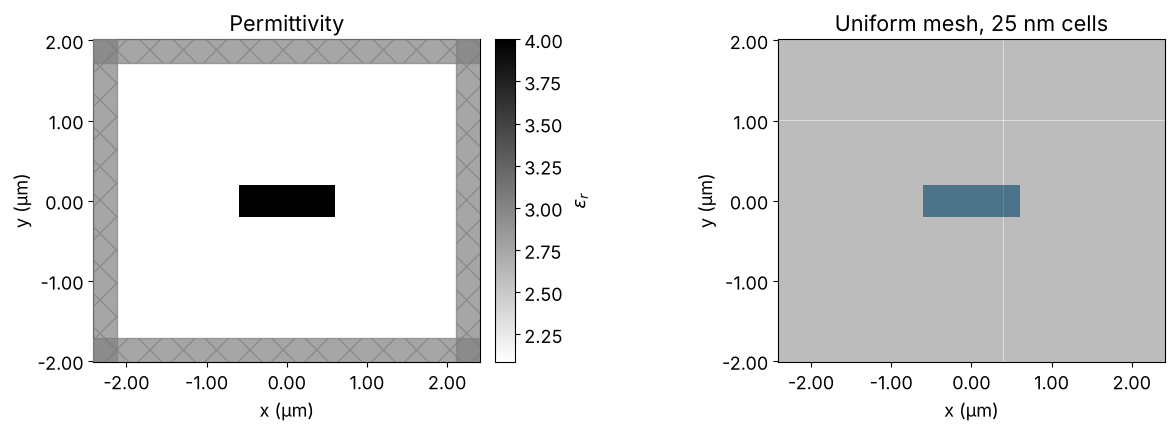

In [22]:
wl_wg   = 1.55
n_sin   = 2.00
n_sio2  = 1.444
W_wg    = 1.2      # width  (along x)
H_wg    = 0.4      # height (along y)

def make_wg_solver(width, height, wavelength, n_core, n_clad, num_modes=4, dl=0.025):
    # Build a rectangular waveguide (core along z) and return a ready-to-run ModeSolver.
    # Uniform mesh with cells of dl x dl µm. About 1.5 µm of cladding is kept on each side of the core.
    margin = 1.5 + dl / 2      # the extra dl/2 puts the core edges in the MIDDLE of a cell (see the note below)
    core = td.Structure(
        geometry=td.Box(center=(0, 0, 0), size=(width, height, td.inf)),
        medium=td.Medium(permittivity=n_core**2),
    )
    Lx, Ly = width + 2 * margin, height + 2 * margin
    sim = td.Simulation(
        size=(Lx, Ly, 0),
        structures=[core],
        medium=td.Medium(permittivity=n_clad**2),
        grid_spec=td.GridSpec.uniform(dl=dl),
        run_time=1e-12,
    )
    return ModeSolver(
        simulation=sim,
        plane=td.Box(center=(0, 0, 0), size=(Lx, Ly, 0)),
        mode_spec=td.ModeSpec(num_modes=num_modes, target_neff=n_core),
        freqs=[td.C_0 / wavelength],
    )

wg_solver = make_wg_solver(W_wg, H_wg, wl_wg, n_sin, n_sio2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), tight_layout=True)
wg_solver.simulation.plot_eps(z=0, ax=ax[0]); ax[0].set_title("Permittivity")
wg_solver.simulation.plot_grid(z=0, ax=ax[1]); wg_solver.simulation.plot_structures(z=0, ax=ax[1])
ax[1].set_title("Uniform mesh, 25 nm cells")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

**למה רשת אחידה, ולמה השוליים המוזרים `1.5 + dl/2`?**
בהמשך נסרוק את גובה הליבה בצעדים של 50 nm. עם תאים של 25 nm, כל גובה הוא מספר שלם של תאים, והתוספת `dl/2` גורמת לכל שפה של הליבה ליפול ב**אמצע**
תא, ואף פעם לא בדיוק על גבול בין תאים. כך נמנעים מקפיצות של "מדרגות" (staircasing: שפת ליבה שנופלת בדיוק על גבול תא נספרת כחצי בפנים וחצי בחוץ), והעקומות יוצאות חלקות.
(נסו `td.GridSpec.auto(...)` במקום, והסתכלו על גרף הסריקה: העקומות נעשות משוננות.)

> 💡 ברשת **האוטומטית** התאים **אינם** כולם באותו גודל (הם קטנים יותר באזורים עם מקדם שבירה גבוה). לכן תמיד מבצעים אינטגרל עם `.integrate(...)`, שמשתמש בגודל התאים האמיתי, ולא עם `np.sum`.

### 3.1 פתרון והסתכלות על האופנים

</div>

In [23]:
t0 = time.time()
wg_data = wg_solver.solve()
print(f"solved in {time.time() - t0:.1f} s\n")

neff_wg = wg_data.n_eff.values[0]
for i, n in enumerate(neff_wg):
    print(f"mode {i}:  n_eff = {n:.4f}   guided: {is_guided(n, n_sin, n_sio2)}")

solved in 1.7 s

mode 0:  n_eff = 1.6687   guided: True
mode 1:  n_eff = 1.5850   guided: True
mode 2:  n_eff = 1.4742   guided: True
mode 3:  n_eff = 1.4375   guided: False


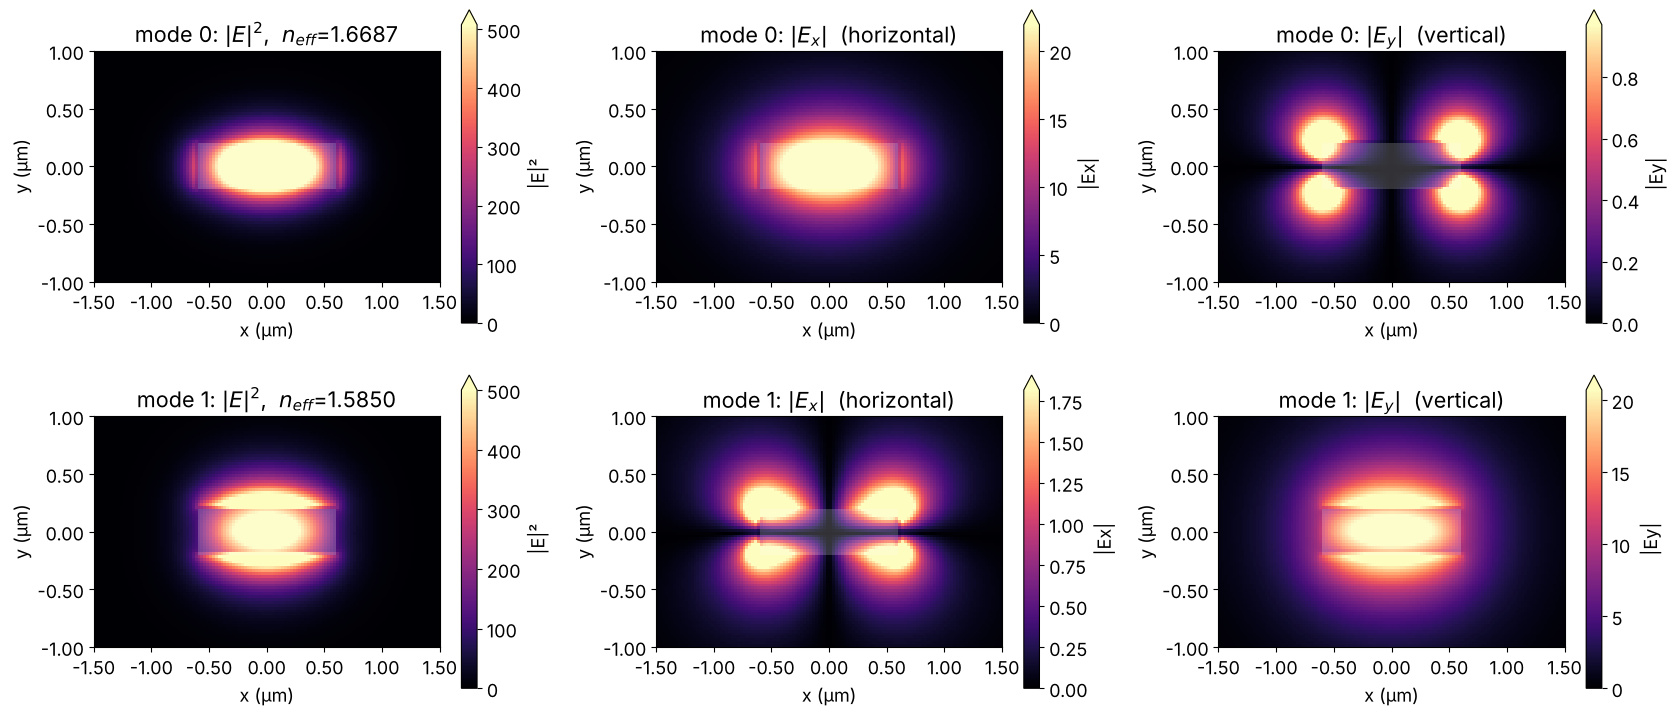

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(17, 7.5), tight_layout=True)
for row, m in enumerate([0, 1]):
    wg_solver.plot_field("E",  val="abs^2", mode_index=m, ax=ax[row, 0])
    wg_solver.plot_field("Ex", val="abs",   mode_index=m, ax=ax[row, 1])
    wg_solver.plot_field("Ey", val="abs",   mode_index=m, ax=ax[row, 2])
    ax[row, 0].set_title(f"mode {m}: $|E|^2$,  $n_{{eff}}$={neff_wg[m]:.4f}")
    ax[row, 1].set_title(f"mode {m}: $|E_x|$  (horizontal)")
    ax[row, 2].set_title(f"mode {m}: $|E_y|$  (vertical)")
for a in ax.flatten():
    a.set_xlim(-1.5, 1.5); a.set_ylim(-1.0, 1.0)
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

**איך קובעים את הקיטוב של אופן במוליך גל:** משווים את **ערכי סרגל הצבע** של $|E_x|$ ושל $|E_y|$.
* אם $|E_x| \gg |E_y|$, השדה החשמלי ברובו **אופקי**: אופן **quasi-TE**.
* אם $|E_y| \gg |E_x|$, השדה ברובו **אנכי**: אופן **quasi-TM**.

בליבה רחבה ושטוחה, האופן בקיטוב אופקי הוא בדרך כלל הכלוא ביותר, כי השדה מקביל לצלע הארוכה של הליבה. האם זה מה שאתם רואים באופן 0?

קוראים לאופנים האלה "quasi" ‏TE/TM משום שבמוליך גל שכולא בשני ממדים **אין** אופן רוחבי טהור; תמיד יש $E_z$ קטן.

### 3.2 כמה מההספק נמצא בתוך הליבה?
בעזרת הכלים מחלק 1.6, נבצע אינטגרל של $|E|^2$ על מלבן הליבה ($|x| \le W/2$ וגם $|y| \le H/2$) ונחלק באינטגרל על כל החלון.
זו דרך פשוטה ומקורבת לומר "איזה חלק מהאור מתקדם בתוך הליבה".

</div>

In [25]:
def fraction_in_rectangle(data, mode_index, width, height):
    # Fraction of |E|^2 inside the rectangle |x| <= width/2, |y| <= height/2.
    I = data.intensity.isel(mode_index=mode_index, f=0).squeeze()       # 2D map
    inside = (np.abs(I.x) <= width / 2) & (np.abs(I.y) <= height / 2)  # 2D mask (True in core)
    return float(I.where(inside, 0).integrate(["x", "y"]) / I.integrate(["x", "y"]))

for m in range(len(neff_wg)):
    print(f"mode {m}:  fraction of |E|^2 inside the core = {fraction_in_rectangle(wg_data, m, W_wg, H_wg):.3f}")

mode 0:  fraction of |E|^2 inside the core = 0.642
mode 1:  fraction of |E|^2 inside the core = 0.374
mode 2:  fraction of |E|^2 inside the core = 0.320
mode 3:  fraction of |E|^2 inside the core = 0.174


<div dir="rtl" style="text-align: right; line-height: 1.6;">

אבני הבניין של הפונקציה:
* `np.abs(I.x) <= width/2` משווה כל **קואורדינטת x**; ‏`np.abs(I.y) <= height/2` כל **קואורדינטת y**.
  החיבור שלהם עם `&` נותן מסכה דו-ממדית שהיא `True` רק בתוך המלבן (xarray מתאים את התוויות `x` ו-`y` אוטומטית).
* `I.where(inside, 0)` שומר את $|E|^2$ בפנים ושם 0 בחוץ, ו-`.integrate(["x","y"])` מבצע את האינטגרל על השטח.

עבור צורה אחרת צריך רק מסכה אחרת. שאלו את עצמכם: איזה תנאי על `x` ועל `y` מתאר את האזור שאתם רוצים?

### 3.3 סריקה: איך האופנים משתנים עם גובה הליבה
אותו מתכון כמו בחלק 2.5: לולאה, פתרון, שמירה, גרף. הפעם נשנה את **הגובה** $H$ ונשאיר את הרוחב קבוע.

</div>

In [26]:
heights = np.arange(0.15, 1.01, 0.05)       # 0.15, 0.20, ..., 1.00 µm
neff_vs_H = []                               # will become a 2D array: [height, mode]

t0 = time.time()
for H in heights:
    data = make_wg_solver(W_wg, H, wl_wg, n_sin, n_sio2, num_modes=4).solve()
    neff_vs_H.append(data.n_eff.values[0])
neff_vs_H = np.array(neff_vs_H)               # list of arrays -> 2D array
print(f"{len(heights)} waveguides solved in {time.time() - t0:.1f} s")
print("array shape (heights, modes):", neff_vs_H.shape)

18 waveguides solved in 31.9 s
array shape (heights, modes): (18, 4)


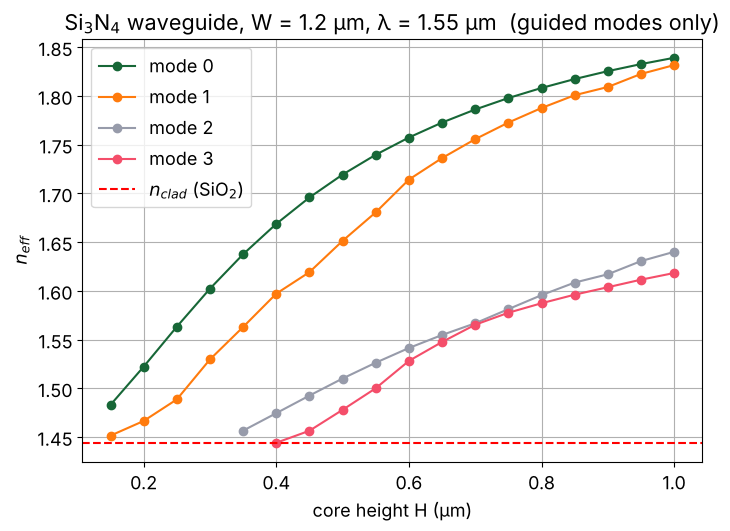

In [27]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for m in range(neff_vs_H.shape[1]):
    neff_m = neff_vs_H[:, m]                 # column m = mode number m
    g = is_guided(neff_m, n_sin, n_sio2)
    ax.plot(heights[g], neff_m[g], "o-", label=f"mode {m}")
ax.axhline(n_sio2, color="r", ls="--", label="$n_{clad}$ (SiO$_2$)")
ax.set_xlabel("core height H (µm)"); ax.set_ylabel("$n_{eff}$")
ax.set_title(f"Si$_3$N$_4$ waveguide, W = {W_wg} µm, λ = {wl_wg} µm  (guided modes only)")
ax.grid(True); ax.legend()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.6;">

**קריאת הגרף:**
* כל עקומה **עולה** עם $H$: ליבה עבה יותר מחזיקה יותר מהשדה בחומר בעל מקדם השבירה הגבוה.
* עקומה **מתחילה** בגובה שבו האופן הופך למולך ($n_{\text{eff}}$ חוצה את $n_{clad}$): זה הקיטעון של האופן הזה.
* ⚠️ **מספרי האופנים ממוינים לפי $n_{\text{eff}}$**, לא לפי סוג האופן. כששני אופנים נחתכים, "אופן 1" בגובה אחד יכול להיות סוג אחר של אופן מאשר "אופן 1" בגובה אחר.
  אם עקומה נראית מוזרה, ציירו את השדות בכמה נקודות כדי לבדוק איזה אופן הוא איזה.

---

</div>

<div dir="rtl" style="text-align: right; line-height: 1.6;">

# 📋 חלק 4: דף עזר, טעויות נפוצות ועזרה

## 4.1 כל המתכון במסך אחד
<div dir="ltr" style="text-align: left;">

```python
import numpy as np, matplotlib.pyplot as plt, tidy3d as td
from tidy3d.plugins.mode import ModeSolver

wl = 1.55                                                     # µm
core = td.Structure(geometry=td.Cylinder(center=(0,0,0), radius=4, length=td.inf, axis=2),   # or td.Box(size=(W,H,td.inf))
                    medium=td.Medium(permittivity=1.46**2))
sim  = td.Simulation(size=(Lx, Ly, 0), structures=[core], medium=td.Medium(permittivity=1.45**2),
                     grid_spec=td.GridSpec.auto(min_steps_per_wvl=12, wavelength=wl), run_time=1e-12)
sim.plot_eps(z=0)                                             # 1. LOOK at the structure
solver = ModeSolver(simulation=sim, plane=td.Box(size=(Lx, Ly, 0)),
                    mode_spec=td.ModeSpec(num_modes=6, target_neff=1.46), freqs=[td.C_0/wl])
data = solver.solve()                                         # 2. SOLVE
neff = data.n_eff.values[0]                                   # 3. NUMBERS
solver.plot_field("E", val="abs^2", mode_index=0)             # 4. PICTURES
I = data.intensity.isel(mode_index=0, f=0).squeeze()          # 5. RAW DATA for your own calculations
```

</div>


## 4.2 טבלת עזר מהירה
| אני רוצה… | קוד |
|---|---|
| חומר עם מקדם שבירה `n` | `td.Medium(permittivity=n**2)` |
| ליבה עגולה לאורך z | `td.Cylinder(center=(0,0,0), radius=a, length=td.inf, axis=2)` |
| ליבה מלבנית לאורך z | `td.Box(center=(0,0,0), size=(W, H, td.inf))` |
| תדר מתוך אורך גל | `td.C_0 / wavelength` |
| רשת אחידה עם תאים בגודל `dl` | `td.GridSpec.uniform(dl=0.025)` |
| להסתכל על המבנה | `sim.plot_eps(z=0)` / `sim.plot_structures(z=0)` / `sim.plot_grid(z=0)` |
| מקדמי שבירה אפקטיביים כ-NumPy | `data.n_eff.values[0]` |
| לצייר שדה | `solver.plot_field("Ey", val="real", mode_index=0, ax=ax)` |
| $\lvert E\rvert^2$ כמערך דו-ממדי | `data.intensity.isel(mode_index=m, f=0).squeeze()` |
| רכיב אחד כמערך דו-ממדי | `data.Ex.isel(mode_index=m, f=0).squeeze()` (מרוכב! השתמשו ב-`np.abs(...)`) |
| קואורדינטות | `I.x.values`, `I.y.values` |
| אינטגרל על כל המישור | `I.integrate(["x", "y"])` |
| אינטגרל על אזור | `I.where(mask, 0).integrate(["x", "y"])` |
| טבלה של הכול | `data.to_dataframe()` |
| לשמור איור | `fig.savefig("my_plot.png", dpi=200, bbox_inches="tight")` |
| לשמור מספרים לקובץ טקסט | `np.savetxt("results.txt", np.column_stack([x, y]))` |

## 4.3 טעויות נפוצות ⚠️
1. **"הפותר מצא N אופנים, אז לסיב יש N אופנים."** לא! הוא **תמיד** מחזיר בדיוק `num_modes` תוצאות. סננו לפי $n_{clad} < n_{\text{eff}} < n_{core}$.
2. **בקשה של מעט מדי אופנים.** אם כל האופנים שהוחזרו מולכים, ייתכן שיש עוד. הגדילו את `num_modes` עד שיופיעו אופנים לא מולכים.
3. **ערכי $n_{\text{eff}}$ כמעט שווים.** אופנים מופיעים לעתים קרובות בקבוצות עם (כמעט) אותו $n_{\text{eff}}$. חשבו מה כל קבוצה מייצגת פיזיקלית לפני שאתם סופרים.
4. **חלון קטן מדי.** השדה צריך לדעוך לכמעט אפס לפני השוליים. אופנים קרובים לקיטעון זולגים רחוק ודורשים חלון גדול יותר. בדקו את $n_{\text{eff}}$ עם חלון גדול יותר.
5. **רשת גסה מדי.** אם התוצאות משתנות כשמעדנים את הרשת, החישוב עוד לא התכנס.
6. **ציר שגוי.** הליבה חייבת לרוץ בכיוון ההתקדמות: `axis=2` לגליל, `td.inf` ברכיב ה-**z** של גודל התיבה, וגודל המישור `(Lx, Ly, 0)`.
7. **שכחתם לעדכן בתוך הלולאה.** אם סורקים את אורך הגל, צריך לשנות בכל סיבוב את `freqs`, את `wavelength` של הרשת, וכל דבר אחר שתלוי בו.
8. **שימוש ב-`np.sum` לאינטגרציה של שדה.** הרשת עשויה להיות לא אחידה; השתמשו ב-`.integrate(["x","y"])`.
9. **עקומות משוננות בסריקה** (staircasing). שפת ליבה שנופלת בדיוק על גבול תא היא "חצי בפנים, חצי בחוץ". השתמשו ברשת עדינה יותר, או ברשת אחידה שבה השפות נופלות באמצע תא (חלק 3).
10. **חוסר זיכרון / איטיות רבה.** הקטינו את `min_steps_per_wvl`, את גודל החלון, או את `num_modes`. בדקו קודם עם הגדרות גסות.
11. **הקרנל קרס או משתנים "לא מוגדרים".** הריצו שוב את התאים **מההתחלה**, לפי הסדר (*Run All*).

## 4.4 איפה ללמוד עוד
* תיעוד ודוגמאות של פותר האופנים של Tidy3D: [docs.flexcompute.com/projects/tidy3d](https://docs.flexcompute.com/projects/tidy3d/en/latest/)
* עזרה מובנית לכל אובייקט: הריצו בתא `help(td.ModeSpec)` או `td.Cylinder?`.
* יסודות NumPy: [numpy.org/doc/stable/user/absolute_beginners.html](https://numpy.org/doc/stable/user/absolute_beginners.html)
* גלריית Matplotlib: [matplotlib.org/stable/gallery](https://matplotlib.org/stable/gallery/index.html)

---
### 🎉 אתם מוכנים
עכשיו אתם יודעים לבנות חתך רוחב, לפתור את האופנים שלו, להפריד בין אופנים מולכים ללא מולכים, לצייר שדות, להוציא את המספרים הגולמיים ולהריץ סריקת פרמטר.
הדרך הטובה ביותר ללמוד עוד היא **לשחק**: שנו את מקדמי השבירה, את הצורה, את אורך הגל, ובדקו מה קורה.

<sub>Bar-Ilan University 2026 · Optical Communication 83-466 · Dr. Boris Desiatov</sub>

</div>